# 01. 용접 공정 이상탐지 7개 모델 비교 (고정 설정 + Early Stopping)

- **Fit(학습구간) 5,200건**: 2020-03-24~03-27. Scaler는 Fit에서만 학습한다.
- **Calibration(임계값 보정구간) 3,270건**: 03-30~03-31. 딥러닝 Early Stopping 및 모델별 Threshold 보정.
- **Holdout(후속 평가구간) 3,469건**: 04-02, 04-03, 04-07. Calibration 공동 1위 모델의 날짜별 실제 불량건수 대비 이상탐지건수 차이를 비교하여 최종 선택한다.
- 모델: AE, Isolation Forest, LOF, PCA, KNN, LSTM-AE, Predictive LSTM.
- **하이퍼파라미터/Scaler/Sequence/Hidden 탐색 없음**. 사전에 고정한 대표 설정 1개씩만 학습한다.
- **Early Stopping은 AE/LSTM-AE/Predictive LSTM에만 적용**. 나머지 전통모델은 조기 종료 개념이 없다.
- Threshold는 Fit 이상점수의 분위수 후보를 Calibration의 일별 집계 오차로 선택한다.
- 4월은 최종모델 2차 선택에 쓰이므로 독립 Test라고 주장하지 않는다.
- 개별 불량 정답이 없어 행 단위 F1/FP/FN을 산출할 수 없다.

**Predictive LSTM은 02와 동일하게 AE fallback 없이 평가:** 각 날짜 첫 10개 행은 `warmup_no_prediction`(점수·이상탐지 NaN)으로 남기고 일별 이상탐지 집계에서 제외한다. 원본 3,469행은 모두 CSV로 저장한다.


In [29]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 시스템에 설치된 폰트 이름 확인
# font_list = [font.name for font in fm.fontManager.ttflist]
# print(font_list)

plt.rcParams['font.family'] = 'NanumGothic'  
plt.rcParams['axes.unicode_minus'] = False


In [30]:

# 0. Imports / reproducibility / search config

import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import math
import random
import time
from copy import deepcopy
from datetime import datetime, timezone
from itertools import product
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import MinMaxScaler, StandardScaler, FunctionTransformer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

ROOT_DIR = Path(".").resolve()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT_DIR = ROOT_DIR / "outputs" / RUN_ID
DIRS = {name: OUT_DIR / name for name in ["metrics", "predictions", "models", "figures", "data"]}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "weld force(bar)",
    "weld current(kA)",
    "weld Voltage(v)",
    "weld time(ms)",
]
GROUP_KEYS = ["date", "Machine_Name", "Item No"]
SORT_COLUMNS = ["date", "Machine_Name", "Item No", "idx", "source_row"]

TRAIN_DATES = pd.to_datetime([
    "2020-03-24", "2020-03-25", "2020-03-26",
    "2020-03-27", "2020-03-30", "2020-03-31",
]).normalize()
TEST_DATES = pd.to_datetime([
    "2020-04-02", "2020-04-03", "2020-04-07",
]).normalize()

# Train 내부 모델선택 구간. 외부 Validation 세트가 아니라 Train 내부 calibration입니다.
FIT_DATES = pd.to_datetime([
    "2020-03-24", "2020-03-25", "2020-03-26", "2020-03-27",
]).normalize()
CAL_DATES = pd.to_datetime(["2020-03-30", "2020-03-31"]).normalize()


# 모델별 대표 설정 고정: 하이퍼파라미터 탐색을 수행하지 않음
# 딥러닝 모델은 Calibration loss 기준 Early Stopping만 적용
# Threshold는 모델마다 Fit score의 분위수 후보를 Calibration에서 보정

MAX_EPOCHS = {"ae": 500, "lstm": 300}
THRESHOLD_Q_GRID = np.linspace(0.9900, 0.9999, 500)

AE_FIXED = dict(scaler="minmax", hidden_dim=3, latent_dim=2, depth=1,
                dropout=0.0, activation="rrelu", batch_size=64, lr=1e-2, patience=20)
LSTMAE_FIXED = dict(scaler="minmax", sequence_length=20, hidden_dim=16,
                    num_layers=1, dropout=0.0, batch_size=64, lr=1e-3,
                    patience=20, score_type="mse")
PRED_FIXED = dict(scaler="standard", sequence_length=10, hidden_dim=32,
                  num_layers=1, dropout=0.2, batch_size=32, lr=1e-3,
                  patience=10, score_type="mae")

# 기존 코드의 결과저장 형식을 유지하기 위한 설정 키 목록
AE_SPACE = {k: [v] for k, v in AE_FIXED.items()}
LSTMAE_SPACE = {k: [v] for k, v in LSTMAE_FIXED.items()}
PRED_SPACE = {k: [v] for k, v in PRED_FIXED.items()}
SEARCH_BUDGET = {"ae_trials": 1, "lstmae_trials": 1, "predictive_trials": 1}

SCORE_BATCH_SIZE = 2048


def save_csv(df, path):
    df.to_csv(path, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")


def write_json(obj, path):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

print("OUT_DIR:", OUT_DIR)
print("Search budget:", SEARCH_BUDGET)


DEVICE: cuda
OUT_DIR: /home/kampuser/welder_source_code/Untitled Folder/outputs/20261008T125309_360963Z
Search budget: {'ae_trials': 1, 'lstmae_trials': 1, 'predictive_trials': 1}


In [31]:

# 1. Load / audit / Train-Test split

def resolve_input():
    candidates = []
    for folder in [ROOT_DIR, ROOT_DIR / "data", Path("/mnt/data")]:
        if not folder.exists():
            continue
        for pattern in ["Welding Data Set_01*.xlsx", "*Welding*Data*Set*.xlsx"]:
            for p in folder.glob(pattern):
                if p.name.startswith("~$") or "scaled" in p.name.lower():
                    continue
                candidates.append(p.resolve())
    candidates = sorted(set(candidates), key=lambda p: (len(p.name), p.name))
    if not candidates:
        raise FileNotFoundError("Welding Data Set_01.xlsx를 찾지 못했습니다.")
    return candidates[0]

INPUT_PATH = resolve_input()
print("INPUT:", INPUT_PATH)

raw_df = pd.read_excel(INPUT_PATH, sheet_name="Raw data")
result_df = pd.read_excel(INPUT_PATH, sheet_name="result")

raw_df.columns = [" ".join(str(c).split()) for c in raw_df.columns]
result_df.columns = [" ".join(str(c).split()) for c in result_df.columns]

raw_df["source_row"] = np.arange(2, len(raw_df) + 2)
raw_df["working time"] = pd.to_datetime(raw_df["working time"], errors="raise")
raw_df["date"] = raw_df["working time"].dt.normalize()
result_df["working time"] = pd.to_datetime(result_df["working time"], errors="raise")
result_df["date"] = result_df["working time"].dt.normalize()

for c in FEATURES:
    raw_df[c] = pd.to_numeric(raw_df[c], errors="raise")

if raw_df[FEATURES].isna().any().any():
    raise ValueError("주요 공정변수에 결측치가 있습니다.")

raw_df = raw_df.sort_values(SORT_COLUMNS, kind="mergesort").reset_index(drop=True)
raw_df["split"] = np.select(
    [raw_df["date"].isin(TRAIN_DATES), raw_df["date"].isin(TEST_DATES)],
    ["train", "test"],
    default="unassigned",
)
if raw_df["split"].eq("unassigned").any():
    raise ValueError("Train/Test에 배정되지 않은 날짜가 있습니다.")

frames = {
    "train": raw_df.loc[raw_df["split"].eq("train")].copy().reset_index(drop=True),
    "test": raw_df.loc[raw_df["split"].eq("test")].copy().reset_index(drop=True),
}
assert len(frames["train"]) == 8470, len(frames["train"])
assert len(frames["test"]) == 3469, len(frames["test"])

fit_frame = frames["train"].loc[frames["train"]["date"].isin(FIT_DATES)].copy().reset_index(drop=True)
cal_frame = frames["train"].loc[frames["train"]["date"].isin(CAL_DATES)].copy().reset_index(drop=True)
assert len(fit_frame) == 5200
assert len(cal_frame) == 3270

reported_daily = (
    result_df.groupby("date", as_index=False)["defect"].sum()
    .rename(columns={"defect": "actual_defect_count"})
)
production_daily = (
    raw_df.groupby(["date", "split"], as_index=False).size()
    .rename(columns={"size": "production_count"})
)
daily_truth_df = production_daily.merge(reported_daily, on="date", how="left")
daily_truth_df["actual_count_known"] = daily_truth_df["actual_defect_count"].notna()
daily_truth_df["actual_count_status"] = np.where(
    daily_truth_df["actual_count_known"], "recorded_aggregate", "unknown_not_zero"
)

print("Train rows:", len(frames["train"]))
print("Internal fit rows:", len(fit_frame))
print("Internal calibration rows:", len(cal_frame))
print("Test rows:", len(frames["test"]))
display(daily_truth_df)


INPUT: /home/kampuser/welder_source_code/Untitled Folder/Welding Data Set_01.xlsx
Train rows: 8470
Internal fit rows: 5200
Internal calibration rows: 3270
Test rows: 3469


,date,split,production_count,actual_defect_count,actual_count_known,actual_count_status
0,2020-03-24,train,1200,4.0,True,recorded_aggregate
1,2020-03-25,train,1352,8.0,True,recorded_aggregate
2,2020-03-26,train,1000,7.0,True,recorded_aggregate
3,2020-03-27,train,1648,NaN,False,unknown_not_zero
4,2020-03-30,train,1470,4.0,True,recorded_aggregate
5,2020-03-31,train,1800,5.0,True,recorded_aggregate
6,2020-04-02,test,2000,4.0,True,recorded_aggregate
7,2020-04-03,test,800,4.0,True,recorded_aggregate
8,2020-04-07,test,669,3.0,True,recorded_aggregate


In [32]:

# 2. Common helpers

def make_scaler(name):
    if name == "minmax":
        return MinMaxScaler()
    if name == "standard":
        return StandardScaler()
    if name == "none":
        # 아무 변환도 하지 않는 Identity Transformer
        return FunctionTransformer(validate=False)

    raise ValueError(f"Unknown scaler: {name}")


def fit_scaler(name, fit_values):
    scaler = make_scaler(name)
    scaler.fit(fit_values)
    return scaler


def fit_scaler(name, fit_values):
    scaler = make_scaler(name)
    scaler.fit(fit_values)
    return scaler


def check_scores(scores, n=None):
    scores = np.asarray(scores, dtype=float).reshape(-1)
    if n is not None and len(scores) != n:
        raise ValueError(f"score length mismatch: {len(scores)} != {n}")
    if not np.isfinite(scores).all():
        raise ValueError("anomaly score contains NaN/Inf")
    return scores


def point_error(pred, target, score_type="mse"):
    diff = pred - target
    if score_type == "mse":
        return (diff ** 2).mean(dim=-1)
    if score_type == "mae":
        return diff.abs().mean(dim=-1)
    raise ValueError(score_type)


def np_point_error(pred, target, score_type="mse"):
    diff = np.asarray(pred) - np.asarray(target)
    if score_type == "mse":
        return np.mean(diff ** 2, axis=-1)
    if score_type == "mae":
        return np.mean(np.abs(diff), axis=-1)
    raise ValueError(score_type)


def build_prediction_table(frame, scores, threshold, model_name, score_source=None):
    scores = check_scores(scores, len(frame))
    keep = ["source_row", "idx", "date", "working time", "Machine_Name", "Item No"] + FEATURES
    out = frame[keep].copy().reset_index(drop=True)
    out["model_name"] = model_name
    out["anomaly_score"] = scores
    out["threshold"] = float(threshold)
    out["anomaly_flag"] = (scores >= threshold).astype(np.int8)
    out["score_source"] = score_source if score_source is not None else model_name
    return out


def evaluate_daily(predictions, truth=daily_truth_df):
    day_pred = predictions.groupby("date", as_index=False).agg(
        predicted_anomaly_count=("anomaly_flag", "sum"),
        production_count_pred=("source_row", "size"),
    )
    daily = day_pred.merge(
        truth[["date", "actual_defect_count", "actual_count_known"]],
        on="date", how="left", validate="one_to_one"
    )
    daily["evaluation_available"] = daily["actual_count_known"].fillna(False)
    daily["error"] = (
        daily["predicted_anomaly_count"] - daily["actual_defect_count"]
    ).where(daily["evaluation_available"])
    daily["absolute_error"] = daily["error"].abs()
    daily["alarm_rate"] = daily["predicted_anomaly_count"] / daily["production_count_pred"]
    eligible = daily.loc[daily["evaluation_available"]].copy()
    metrics = {
        "n_days_evaluated": int(len(eligible)),
        "daily_mae": float(eligible["absolute_error"].mean()) if len(eligible) else np.nan,
        "daily_rmse": float(np.sqrt(np.mean(eligible["error"].to_numpy() ** 2))) if len(eligible) else np.nan,
        "daily_bias": float(eligible["error"].mean()) if len(eligible) else np.nan,
        "actual_count_evaluated_days": int(eligible["actual_defect_count"].sum()) if len(eligible) else 0,
        "predicted_count_evaluated_days": int(eligible["predicted_anomaly_count"].sum()) if len(eligible) else 0,
        "absolute_total_count_error": float(abs(eligible["error"].sum())) if len(eligible) else np.nan,
        "worst_day_abs_error": float(eligible["absolute_error"].max()) if len(eligible) else np.nan,
    }
    return daily.sort_values("date").reset_index(drop=True), metrics


def metric_sort_key(m):
    return (
        float(m["daily_mae"]),
        float(m["daily_rmse"]),
        float(m["absolute_total_count_error"]),
        float(m["worst_day_abs_error"]),
        abs(float(m["daily_bias"])),
    )


def select_threshold_q(reference_scores, eval_frame, eval_scores, model_name, q_grid=THRESHOLD_Q_GRID):
    reference_scores = check_scores(reference_scores)
    eval_scores = check_scores(eval_scores, len(eval_frame))
    rows = []
    best = None
    for q in q_grid:
        threshold = float(np.quantile(reference_scores, float(q)))
        pred = build_prediction_table(eval_frame, eval_scores, threshold, model_name)
        daily, metrics = evaluate_daily(pred)
        row = {"q": float(q), "threshold": threshold, **metrics}
        rows.append(row)
        key = metric_sort_key(metrics) + (-float(q),)
        if best is None or key < best[0]:
            best = (key, row, pred, daily)
    return best[1], pd.DataFrame(rows), best[2], best[3]


def _ordered_group_positions(frame):
    work = frame.reset_index(drop=True).copy()
    work["_pos"] = np.arange(len(work), dtype=np.int64)
    return [g["_pos"].to_numpy(dtype=np.int64) for _, g in work.groupby(GROUP_KEYS, sort=False)]


def build_lstm_ae_sequences(frame, values, sequence_length):
    seqs, positions = [], []
    for pos in _ordered_group_positions(frame):
        for end in range(sequence_length - 1, len(pos)):
            chosen = pos[end - sequence_length + 1:end + 1]
            seqs.append(values[chosen])
            positions.append(int(pos[end]))
    return np.asarray(seqs, dtype=np.float32), np.asarray(positions, dtype=np.int64)


def build_predictive_sequences(frame, values, sequence_length):
    seqs, targets, positions = [], [], []
    for pos in _ordered_group_positions(frame):
        for end in range(sequence_length, len(pos)):
            chosen = pos[end - sequence_length:end]
            seqs.append(values[chosen])
            targets.append(values[pos[end]])
            positions.append(int(pos[end]))
    return (
        np.asarray(seqs, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(positions, dtype=np.int64),
    )


def make_hybrid_prediction(
    frame,
    fallback_scores, fallback_threshold,
    seq_scores, seq_positions, seq_threshold,
    model_name,
):
    n = len(frame)
    scores = np.asarray(fallback_scores, dtype=float).copy()
    thresholds = np.full(n, float(fallback_threshold), dtype=float)
    flags = (scores >= fallback_threshold).astype(np.int8)
    source = np.array(["AE_fallback"] * n, dtype=object)
    sequence_available = np.zeros(n, dtype=bool)

    seq_scores = check_scores(seq_scores, len(seq_positions))
    scores[seq_positions] = seq_scores
    thresholds[seq_positions] = float(seq_threshold)
    flags[seq_positions] = (seq_scores >= seq_threshold).astype(np.int8)
    source[seq_positions] = model_name
    sequence_available[seq_positions] = True

    keep = ["source_row", "idx", "date", "working time", "Machine_Name", "Item No"] + FEATURES
    out = frame[keep].copy().reset_index(drop=True)
    out["model_name"] = model_name
    out["anomaly_score"] = scores
    out["threshold"] = thresholds
    out["anomaly_flag"] = flags
    out["score_source"] = source
    out["sequence_available"] = sequence_available
    return out


def select_hybrid_threshold_q(
    reference_seq_scores,
    eval_frame, eval_seq_scores, eval_seq_positions,
    fallback_eval_scores, fallback_threshold,
    model_name,
    q_grid=THRESHOLD_Q_GRID,
):
    reference_seq_scores = check_scores(reference_seq_scores)
    rows = []
    best = None
    for q in q_grid:
        seq_threshold = float(np.quantile(reference_seq_scores, float(q)))
        pred = make_hybrid_prediction(
            eval_frame,
            fallback_eval_scores, fallback_threshold,
            eval_seq_scores, eval_seq_positions, seq_threshold,
            model_name,
        )
        daily, metrics = evaluate_daily(pred)
        row = {"q": float(q), "threshold": seq_threshold, **metrics}
        rows.append(row)
        key = metric_sort_key(metrics) + (-float(q),)
        if best is None or key < best[0]:
            best = (key, row, pred, daily)
    return best[1], pd.DataFrame(rows), best[2], best[3]



def make_pure_predictive_prediction(frame, seq_scores, seq_positions, seq_threshold, model_name="Predictive_LSTM"):
    """02 방식: 시퀀스 미생성 행은 미예측(NaN), AE fallback 금지."""
    seq_positions = np.asarray(seq_positions, dtype=int)
    seq_scores = check_scores(seq_scores, len(seq_positions))
    if len(np.unique(seq_positions)) != len(seq_positions):
        raise ValueError("Duplicated sequence target positions")
    keep = ["source_row", "idx", "date", "working time", "Machine_Name", "Item No"] + FEATURES
    out = frame[keep].copy().reset_index(drop=True)
    out["model_name"] = model_name
    out["anomaly_score"] = np.nan
    out["threshold"] = float(seq_threshold)
    out["anomaly_flag"] = pd.Series(pd.array([pd.NA] * len(out), dtype="Int64"))
    out["score_source"] = "warmup_no_prediction"
    out["sequence_available"] = False
    out.loc[seq_positions, "anomaly_score"] = seq_scores
    out.loc[seq_positions, "anomaly_flag"] = (seq_scores >= seq_threshold).astype(int)
    out.loc[seq_positions, "score_source"] = model_name
    out.loc[seq_positions, "sequence_available"] = True
    return out


def select_pure_predictive_threshold_q(reference_seq_scores, eval_frame, eval_seq_scores,
                                       eval_seq_positions, model_name="Predictive_LSTM",
                                       q_grid=THRESHOLD_Q_GRID):
    """02와 동일: Fit 점수 분위수 -> Calibration의 예측가능 행만 일별 집계."""
    reference_seq_scores = check_scores(reference_seq_scores)
    rows = []
    best = None
    for q in q_grid:
        th = float(np.quantile(reference_seq_scores, float(q)))
        pred = make_pure_predictive_prediction(eval_frame, eval_seq_scores,
                                               eval_seq_positions, th, model_name)
        scored = pred.loc[pred["sequence_available"]].copy()
        daily, metrics = evaluate_daily(scored)
        row = {"q": float(q), "threshold": th, **metrics}
        rows.append(row)
        # 02의 정렬 우선순위: Daily MAE -> RMSE -> 총량오차 -> threshold(오름차순)
        key = (float(metrics["daily_mae"]), float(metrics["daily_rmse"]),
               float(metrics["absolute_total_count_error"]), th)
        if best is None or key < best[0]:
            best = (key, row, pred, daily)
    return best[1], pd.DataFrame(rows), best[2], best[3]

def sample_configs(space, n_trials, anchors=None, seed=SEED):
    keys = list(space)
    combos = [dict(zip(keys, vals)) for vals in product(*(space[k] for k in keys))]
    rng = random.Random(seed)
    rng.shuffle(combos)
    picked = []
    seen = set()
    for cfg in (anchors or []) + combos:
        sig = json.dumps(cfg, sort_keys=True)
        if sig in seen:
            continue
        seen.add(sig)
        picked.append(cfg)
        if len(picked) >= n_trials:
            break
    return picked

print("Helpers ready")


Helpers ready


In [33]:

# 3. Flexible AutoEncoder: architecture + scaler + training training

def make_activation(name):
    if name == "relu":
        return nn.ReLU()
    if name == "rrelu":
        return nn.RReLU()
    raise ValueError(name)


class FlexibleAutoEncoder(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=8, latent_dim=2, depth=1, dropout=0.0, activation="relu"):
        super().__init__()
        act = lambda: make_activation(activation)
        layers = []
        if int(depth) == 1:
            layers += [nn.Linear(input_dim, hidden_dim), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(hidden_dim, latent_dim), act()]
            layers += [nn.Linear(latent_dim, hidden_dim), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(hidden_dim, input_dim)]
        elif int(depth) == 2:
            h2 = max(int(latent_dim) + 1, int(hidden_dim) // 2)
            layers += [nn.Linear(input_dim, hidden_dim), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(hidden_dim, h2), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(h2, latent_dim), act()]
            layers += [nn.Linear(latent_dim, h2), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(h2, hidden_dim), act(), nn.Dropout(dropout)]
            layers += [nn.Linear(hidden_dim, input_dim)]
        else:
            raise ValueError("depth must be 1 or 2")
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


@torch.no_grad()
def ae_scores(model, values, score_type="mse"):
    values = np.ascontiguousarray(values, dtype=np.float32)
    out = []
    model.eval()
    for start in range(0, len(values), SCORE_BATCH_SIZE):
        batch = torch.from_numpy(values[start:start + SCORE_BATCH_SIZE]).to(DEVICE)
        recon = model(batch)
        s = point_error(recon, batch, score_type)
        out.append(s.cpu().numpy())
    return check_scores(np.concatenate(out), len(values))


def train_ae_es(cfg, fit_x, cal_x):
    seed_everything()
    model = FlexibleAutoEncoder(
        input_dim=4,
        hidden_dim=cfg["hidden_dim"],
        latent_dim=cfg["latent_dim"],
        depth=cfg["depth"],
        dropout=cfg["dropout"],
        activation=cfg["activation"],
    ).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(np.ascontiguousarray(fit_x, dtype=np.float32))),
        batch_size=int(cfg["batch_size"]), shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0,
    )
    opt = torch.optim.Adam(model.parameters(), lr=float(cfg["lr"]))
    criterion = nn.MSELoss()
    best_state, best_loss, best_epoch = None, float("inf"), 0
    bad = 0
    hist = []
    for epoch in range(1, MAX_EPOCHS["ae"] + 1):
        model.train(); total = 0.0; n = 0
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            recon = model(batch)
            loss = criterion(recon, batch)
            if not torch.isfinite(loss):
                raise FloatingPointError("AE loss NaN/Inf")
            loss.backward(); opt.step()
            total += float(loss.detach().item()) * len(batch); n += len(batch)
        fit_loss = total / n
        cal_loss = float(ae_scores(model, cal_x, "mse").mean())
        improved = cal_loss < best_loss - 1e-6
        if improved:
            best_loss = cal_loss; best_epoch = epoch; bad = 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        hist.append({"epoch": epoch, "fit_mse": fit_loss, "cal_mse": cal_loss, "bad_epochs": bad})
        if bad >= int(cfg["patience"]):
            break
    model.load_state_dict(best_state); model.eval()
    return model, pd.DataFrame(hist), int(best_epoch), float(best_loss)


def train_ae_fixed(cfg, values, epochs):
    seed_everything()
    model = FlexibleAutoEncoder(
        input_dim=4,
        hidden_dim=cfg["hidden_dim"], latent_dim=cfg["latent_dim"],
        depth=cfg["depth"], dropout=cfg["dropout"], activation=cfg["activation"],
    ).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(np.ascontiguousarray(values, dtype=np.float32))),
        batch_size=int(cfg["batch_size"]), shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0,
    )
    opt = torch.optim.Adam(model.parameters(), lr=float(cfg["lr"]))
    criterion = nn.MSELoss()
    for _ in range(int(epochs)):
        model.train()
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(batch), batch)
            loss.backward(); opt.step()
    model.eval()
    return model


# ---- AE 고정 설정 1회 학습 + Early Stopping ----
ae_trials = [AE_FIXED.copy()]
ae_trial_rows = []
ae_trial_details = {}

for trial_id, cfg in enumerate(ae_trials, 1):
    t0 = time.time()
    scaler = fit_scaler(cfg["scaler"], fit_frame[FEATURES])
    fit_x = scaler.transform(fit_frame[FEATURES]).astype(np.float32)
    cal_x = scaler.transform(cal_frame[FEATURES]).astype(np.float32)
    try:
        model, hist, best_epoch, best_loss = train_ae_es(cfg, fit_x, cal_x)
        fit_scores = ae_scores(model, fit_x, "mse")
        cal_scores = ae_scores(model, cal_x, "mse")
        th_best, th_table, cal_pred, cal_daily = select_threshold_q(
            fit_scores, cal_frame, cal_scores, f"AE_trial_{trial_id}"
        )
        row = {
            "trial": trial_id, **cfg,
            "best_epoch": best_epoch,
            "best_cal_recon_mse": best_loss,
            "selected_q": th_best["q"],
            "cal_daily_mae": th_best["daily_mae"],
            "cal_daily_rmse": th_best["daily_rmse"],
            "cal_total_error": th_best["absolute_total_count_error"],
            "cal_worst_day": th_best["worst_day_abs_error"],
            "seconds": time.time() - t0,
            "status": "ok",
        }
        ae_trial_details[trial_id] = (cfg, best_epoch, th_best["q"], deepcopy(model.state_dict()), scaler, fit_scores, cal_scores)
    except Exception as e:
        row = {"trial": trial_id, **cfg, "status": "failed", "error": repr(e), "seconds": time.time() - t0}
    ae_trial_rows.append(row)
    print(f"AE trial {trial_id}/{len(ae_trials)} -> {row.get('status')} MAE={row.get('cal_daily_mae')}")

ae_training_df = pd.DataFrame(ae_trial_rows)
ae_ok = ae_training_df.loc[ae_training_df["status"].eq("ok")].copy()
ae_ok = ae_ok.sort_values(
    ["cal_daily_mae", "cal_daily_rmse", "cal_total_error", "cal_worst_day", "best_cal_recon_mse", "best_epoch"],
    kind="mergesort"
).reset_index(drop=True)
if ae_ok.empty:
    raise RuntimeError("AE training failed")

AE_BEST = ae_ok.iloc[0].to_dict()
AE_BEST_CFG = {k: AE_BEST[k] for k in AE_SPACE}
AE_BEST_EPOCH = int(AE_BEST["best_epoch"])
AE_BEST_Q = float(AE_BEST["selected_q"])
print("\nBEST AE")
display(pd.DataFrame([AE_BEST]))
save_csv(ae_training_df, DIRS["metrics"] / "AE_training_summary.csv")
write_json({"config": AE_BEST_CFG, "best_epoch": AE_BEST_EPOCH, "selected_q": AE_BEST_Q}, DIRS["models"] / "AE_best_config.json")

# Internal best AE를 LSTM warm-up fallback으로 고정
internal_ae_model, _, _, _, internal_ae_scaler, internal_ae_fit_scores, internal_ae_cal_scores = ae_trial_details[int(AE_BEST["trial"])]
internal_ae_threshold = float(np.quantile(internal_ae_fit_scores, AE_BEST_Q))
print("Internal AE fallback threshold:", internal_ae_threshold)


AE trial 1/1 -> ok MAE=2.0

BEST AE


,trial,scaler,hidden_dim,latent_dim,depth,dropout,activation,batch_size,lr,patience,best_epoch,best_cal_recon_mse,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,seconds,status
0,1,minmax,3,2,1,0.0,rrelu,64,0.01,20,96,0.001963,0.998452,2.0,2.828427,4.0,4.0,52.985048,ok


Internal AE fallback threshold: 0.11359853297472


In [34]:
# 4. Classical models: small Train-internal training

def classical_score_model(kind, cfg, fit_x, eval_x):
    if kind == "IsolationForest":
        model = IsolationForest(
            n_estimators=int(cfg["n_estimators"]),
            max_samples=cfg["max_samples"],
            contamination="auto",
            random_state=SEED,
            n_jobs=-1,
        ).fit(fit_x)

        return (
            model,
            -model.score_samples(fit_x),
            -model.score_samples(eval_x),
        )

    if kind == "LOF":
        model = LocalOutlierFactor(
            n_neighbors=int(cfg["n_neighbors"]),
            novelty=True,
            n_jobs=-1,
        ).fit(fit_x)

        return (
            model,
            -model.score_samples(fit_x),
            -model.score_samples(eval_x),
        )

    if kind == "PCA":
        model = PCA(
            n_components=int(cfg["n_components"]),
            random_state=SEED,
        ).fit(fit_x)

        def sc(x):
            z = model.transform(x)
            recon = model.inverse_transform(z)

            return np.mean(
                (np.asarray(x) - recon) ** 2,
                axis=1
            )

        return model, sc(fit_x), sc(eval_x)

    if kind == "KNN":
        k = int(cfg["n_neighbors"])

        model = NearestNeighbors(
            n_neighbors=k + 1,
            n_jobs=-1
        ).fit(fit_x)

        # Fit 자기 자신 포함 → k+1
        fd, _ = model.kneighbors(
            fit_x,
            n_neighbors=k + 1
        )

        # Calibration에는 자기 자신 없음 → k
        ed, _ = model.kneighbors(
            eval_x,
            n_neighbors=k
        )

        return model, fd[:, -1], ed[:, -1]

    raise ValueError(kind)


# Classical model representative configurations

CLASSICAL_SPACES = {

    "IsolationForest": [
        {
            "scaler": "none",
            "n_estimators": 300,
            "max_samples": "auto",
        }
    ],

    "LOF": [
        {
            "scaler": "standard",
            "n_neighbors": 20,
        }
    ],

    "PCA": [
        {
            "scaler": "standard",
            "n_components": 2,
        }
    ],

    "KNN": [
        {
            "scaler": "standard",
            "n_neighbors": 20,
        }
    ],
}


classical_best = {}
classical_training_rows = []


# Train / Calibration

for kind, configs in CLASSICAL_SPACES.items():

    local_rows = []

    for trial_id, cfg in enumerate(configs, 1):

        try:
            # Scaling
            scaler = fit_scaler(
                cfg["scaler"],
                fit_frame[FEATURES]
            )

            fit_x = scaler.transform(
                fit_frame[FEATURES]
            )

            cal_x = scaler.transform(
                cal_frame[FEATURES]
            )

            # Model training + anomaly score
            model, fit_score, cal_score = classical_score_model(
                kind,
                cfg,
                fit_x,
                cal_x
            )

            # Threshold calibration
            th_best, _, _, _ = select_threshold_q(
                fit_score,
                cal_frame,
                cal_score,
                kind
            )

            row = {
                "model": kind,
                "trial": trial_id,
                **cfg,

                "selected_q": th_best["q"],
                "cal_daily_mae": th_best["daily_mae"],
                "cal_daily_rmse": th_best["daily_rmse"],
                "cal_total_error": th_best[
                    "absolute_total_count_error"
                ],
                "cal_worst_day": th_best[
                    "worst_day_abs_error"
                ],

                "status": "ok",
            }

        except Exception as e:

            row = {
                "model": kind,
                "trial": trial_id,
                **cfg,
                "status": "failed",
                "error": repr(e),
            }

        local_rows.append(row)
        classical_training_rows.append(row)


    # Best configuration


    local = pd.DataFrame(local_rows)

    ok = (
        local.loc[
            local["status"].eq("ok")
        ]
        .sort_values(
            [
                "cal_daily_mae",
                "cal_daily_rmse",
                "cal_total_error",
                "cal_worst_day",
            ],
            kind="mergesort"
        )
    )

    if ok.empty:
        raise RuntimeError(
            f"{kind} training failed"
        )

    classical_best[kind] = (
        ok.iloc[0].to_dict()
    )

    print(f"\nBEST {kind}")
    display(ok.head(5))


# Save results


classical_training_df = pd.DataFrame(
    classical_training_rows
)

save_csv(
    classical_training_df,
    DIRS["metrics"] / "classical_training_summary.csv"
)

write_json(
    classical_best,
    DIRS["models"] / "classical_best_configs.json"
)


BEST IsolationForest


,model,trial,scaler,n_estimators,max_samples,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,status
0,IsolationForest,1,none,300,auto,0.998452,2.0,2.828427,4.0,4.0,ok



BEST LOF


,model,trial,scaler,n_neighbors,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,status
0,LOF,1,standard,20,0.995575,1.0,1.414214,2.0,2.0,ok



BEST PCA


,model,trial,scaler,n_components,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,status
0,PCA,1,standard,2,0.998452,2.0,2.828427,4.0,4.0,ok



BEST KNN


,model,trial,scaler,n_neighbors,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,status
0,KNN,1,standard,20,0.998134,2.0,2.828427,4.0,4.0,ok


In [35]:

# 5. LSTM model definitions / training helpers

class FlexibleLSTMAutoEncoder(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=32, num_layers=1, dropout=0.0):
        super().__init__()
        recurrent_dropout = float(dropout) if int(num_layers) > 1 else 0.0
        self.encoder = nn.LSTM(
            input_dim, hidden_dim, num_layers=int(num_layers), batch_first=True,
            dropout=recurrent_dropout,
        )
        self.context_dropout = nn.Dropout(float(dropout))
        self.decoder = nn.LSTM(
            hidden_dim, hidden_dim, num_layers=int(num_layers), batch_first=True,
            dropout=recurrent_dropout,
        )
        self.output_dropout = nn.Dropout(float(dropout))
        self.output = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        _, (h, _) = self.encoder(x)
        context = self.context_dropout(h[-1]).unsqueeze(1).repeat(1, x.size(1), 1)
        dec, _ = self.decoder(context)
        return self.output(self.output_dropout(dec))


class FlexiblePredictiveLSTM(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=32, num_layers=1, dropout=0.0):
        super().__init__()
        recurrent_dropout = float(dropout) if int(num_layers) > 1 else 0.0
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, num_layers=int(num_layers), batch_first=True,
            dropout=recurrent_dropout,
        )
        self.dropout = nn.Dropout(float(dropout))
        self.output = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.output(self.dropout(out[:, -1, :]))


@torch.no_grad()
def score_lstm_ae(model, seqs, score_type="mse"):
    out = []
    model.eval()
    for start in range(0, len(seqs), SCORE_BATCH_SIZE):
        batch = torch.from_numpy(np.ascontiguousarray(seqs[start:start + SCORE_BATCH_SIZE])).to(DEVICE)
        recon = model(batch)
        s = point_error(recon[:, -1, :], batch[:, -1, :], score_type)
        out.append(s.cpu().numpy())
    return check_scores(np.concatenate(out), len(seqs))


@torch.no_grad()
def score_predictive(model, seqs, targets, score_type="mse"):
    out = []
    model.eval()
    for start in range(0, len(seqs), SCORE_BATCH_SIZE):
        x = torch.from_numpy(np.ascontiguousarray(seqs[start:start + SCORE_BATCH_SIZE])).to(DEVICE)
        y = torch.from_numpy(np.ascontiguousarray(targets[start:start + SCORE_BATCH_SIZE])).to(DEVICE)
        pred = model(x)
        s = point_error(pred, y, score_type)
        out.append(s.cpu().numpy())
    return check_scores(np.concatenate(out), len(seqs))


def train_lstmae_es(cfg, fit_seq, cal_seq):
    seed_everything()
    model = FlexibleLSTMAutoEncoder(4, cfg["hidden_dim"], cfg["num_layers"], cfg["dropout"]).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(np.ascontiguousarray(fit_seq, dtype=np.float32))),
        batch_size=int(cfg["batch_size"]), shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0,
    )
    opt = torch.optim.Adam(model.parameters(), lr=float(cfg["lr"]))
    criterion = nn.MSELoss()
    best_state, best_loss, best_epoch, bad = None, float("inf"), 0, 0
    hist=[]
    for epoch in range(1, MAX_EPOCHS["lstm"] + 1):
        model.train(); total=0.0; n=0
        for (x,) in loader:
            x=x.to(DEVICE); opt.zero_grad(set_to_none=True)
            recon=model(x); loss=criterion(recon,x)
            if not torch.isfinite(loss): raise FloatingPointError("LSTM-AE loss NaN/Inf")
            loss.backward(); opt.step(); total += float(loss.detach().item())*len(x); n += len(x)
        fit_loss=total/n
        # Early stopping은 학습 objective와 동일하게 full-sequence MSE
        model.eval(); vals=[]
        with torch.no_grad():
            for start in range(0, len(cal_seq), SCORE_BATCH_SIZE):
                b=torch.from_numpy(np.ascontiguousarray(cal_seq[start:start+SCORE_BATCH_SIZE])).to(DEVICE)
                vals.append(((model(b)-b)**2).mean(dim=(1,2)).cpu().numpy())
        cal_loss=float(np.concatenate(vals).mean())
        if cal_loss < best_loss - 1e-6:
            best_loss=cal_loss; best_epoch=epoch; bad=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else: bad += 1
        hist.append({"epoch":epoch,"fit_seq_mse":fit_loss,"cal_seq_mse":cal_loss,"bad_epochs":bad})
        if bad >= int(cfg["patience"]): break
    model.load_state_dict(best_state); model.eval()
    return model, pd.DataFrame(hist), int(best_epoch), float(best_loss)


def train_pred_es(cfg, fit_seq, fit_y, cal_seq, cal_y):
    """02_final_model_predictive_lstm_full과 같은 초기화/학습/ES 구현."""
    # 02는 노트북 시작에 seed를 설정하고, LSTM 생성 전에는 다른 모델을
    # 학습하지 않는다. 01에서는 다른 6개 모델을 학습하므로 여기서 seed 재설정.
    seed_everything(SEED)
    model = FlexiblePredictiveLSTM(
        4, int(cfg["hidden_dim"]), int(cfg["num_layers"]), float(cfg["dropout"])
    ).to(DEVICE)
    train_loader = DataLoader(
        TensorDataset(torch.tensor(fit_seq, dtype=torch.float32),
                      torch.tensor(fit_y, dtype=torch.float32)),
        batch_size=int(cfg["batch_size"]), shuffle=False, drop_last=False,
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=float(cfg["lr"]))
    criterion = nn.MSELoss()

    def eval_mse_02():
        model.eval()
        val_loader = DataLoader(
            TensorDataset(torch.tensor(cal_seq, dtype=torch.float32),
                          torch.tensor(cal_y, dtype=torch.float32)),
            batch_size=1024, shuffle=False, drop_last=False,
        )
        losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                loss = ((pred - yb) ** 2).mean(dim=1)
                losses.append(loss.detach().cpu().numpy())
        return float(np.concatenate(losses).mean())

    best_val, best_epoch, best_state, wait = np.inf, 0, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS["lstm"] + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred = model(xb)
            loss = criterion(pred, yb)
            if not torch.isfinite(loss):
                raise FloatingPointError("Predictive LSTM loss NaN/Inf")
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        train_loss = float(np.mean(train_losses))
        val_loss = eval_mse_02()
        history.append({"epoch": epoch, "fit_prediction_mse": train_loss,
                        "cal_prediction_mse": val_loss})
        # 02의 EarlyStopping min_delta=1e-10 사용 (01의 기존 1e-6과 다름)
        if val_loss < best_val - 1e-10:
            best_val = val_loss
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= int(cfg["patience"]):
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), int(best_epoch), float(best_val)


def train_lstmae_fixed(cfg, seqs, epochs):
    seed_everything()
    model=FlexibleLSTMAutoEncoder(4,cfg["hidden_dim"],cfg["num_layers"],cfg["dropout"]).to(DEVICE)
    loader=DataLoader(TensorDataset(torch.from_numpy(np.ascontiguousarray(seqs,dtype=np.float32))),
                      batch_size=int(cfg["batch_size"]),shuffle=True,
                      generator=torch.Generator().manual_seed(SEED),num_workers=0)
    opt=torch.optim.Adam(model.parameters(),lr=float(cfg["lr"])); criterion=nn.MSELoss()
    for _ in range(int(epochs)):
        model.train()
        for (x,) in loader:
            x=x.to(DEVICE); opt.zero_grad(set_to_none=True); loss=criterion(model(x),x); loss.backward(); opt.step()
    model.eval(); return model


def train_pred_fixed(cfg, seqs, targets, epochs):
    seed_everything()
    model=FlexiblePredictiveLSTM(4,cfg["hidden_dim"],cfg["num_layers"],cfg["dropout"]).to(DEVICE)
    loader=DataLoader(TensorDataset(torch.from_numpy(np.ascontiguousarray(seqs,dtype=np.float32)),
                                    torch.from_numpy(np.ascontiguousarray(targets,dtype=np.float32))),
                      batch_size=int(cfg["batch_size"]),shuffle=False,num_workers=0)
    opt=torch.optim.Adam(model.parameters(),lr=float(cfg["lr"])); criterion=nn.MSELoss()
    for _ in range(int(epochs)):
        model.train()
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True); loss=criterion(model(x),y); loss.backward(); opt.step()
    model.eval(); return model

print("LSTM helpers ready")


LSTM helpers ready


In [36]:

# 6. LSTM-AE architecture / hyperparameter / threshold search

lstmae_trials = [LSTMAE_FIXED.copy()]
lstmae_rows=[]
lstmae_trial_details={}

for trial_id,cfg in enumerate(lstmae_trials,1):
    t0=time.time()
    try:
        scaler=fit_scaler(cfg["scaler"],fit_frame[FEATURES])
        fit_x=scaler.transform(fit_frame[FEATURES]).astype(np.float32)
        cal_x=scaler.transform(cal_frame[FEATURES]).astype(np.float32)
        fit_seq,fit_pos=build_lstm_ae_sequences(fit_frame,fit_x,int(cfg["sequence_length"]))
        cal_seq,cal_pos=build_lstm_ae_sequences(cal_frame,cal_x,int(cfg["sequence_length"]))
        model,hist,best_epoch,best_loss=train_lstmae_es(cfg,fit_seq,cal_seq)
        fit_score=score_lstm_ae(model,fit_seq,cfg["score_type"])
        cal_score=score_lstm_ae(model,cal_seq,cfg["score_type"])
        th_best,_,_,_=select_hybrid_threshold_q(
            fit_score,
            cal_frame,cal_score,cal_pos,
            internal_ae_cal_scores,internal_ae_threshold,
            f"LSTM_AE_trial_{trial_id}",
        )
        row={"trial":trial_id,**cfg,"best_epoch":best_epoch,"best_cal_seq_mse":best_loss,
             "selected_q":th_best["q"],"cal_daily_mae":th_best["daily_mae"],
             "cal_daily_rmse":th_best["daily_rmse"],"cal_total_error":th_best["absolute_total_count_error"],
             "cal_worst_day":th_best["worst_day_abs_error"],"seconds":time.time()-t0,"status":"ok"}
        lstmae_trial_details[trial_id] = {
            "config": deepcopy(cfg),
            "best_epoch": int(best_epoch),
            "selected_q": float(th_best["q"]),
            "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            "scaler": scaler,
            "fit_scores": fit_score.copy(),
            "cal_scores": cal_score.copy(),
            "fit_positions": fit_pos.copy(),
            "cal_positions": cal_pos.copy(),
        }
    except Exception as e:
        row={"trial":trial_id,**cfg,"status":"failed","error":repr(e),"seconds":time.time()-t0}
    lstmae_rows.append(row)
    print(f"LSTM-AE trial {trial_id}/{len(lstmae_trials)} -> {row.get('status')} MAE={row.get('cal_daily_mae')}")

lstmae_training_df=pd.DataFrame(lstmae_rows)
lstmae_ok=lstmae_training_df.loc[lstmae_training_df["status"].eq("ok")].sort_values(
    ["cal_daily_mae","cal_daily_rmse","cal_total_error","cal_worst_day","best_cal_seq_mse","best_epoch"],
    kind="mergesort"
).reset_index(drop=True)
if lstmae_ok.empty: raise RuntimeError("LSTM-AE training failed")
LSTMAE_BEST=lstmae_ok.iloc[0].to_dict()
LSTMAE_BEST_CFG={k:LSTMAE_BEST[k] for k in LSTMAE_SPACE}
LSTMAE_BEST_EPOCH=int(LSTMAE_BEST["best_epoch"]); LSTMAE_BEST_Q=float(LSTMAE_BEST["selected_q"])
print("\nBEST LSTM-AE")
display(lstmae_ok.head(10))
save_csv(lstmae_training_df,DIRS["metrics"] / "LSTM_AE_training_summary.csv")
write_json({"config":LSTMAE_BEST_CFG,"best_epoch":LSTMAE_BEST_EPOCH,"selected_q":LSTMAE_BEST_Q},
           DIRS["models"] / "LSTM_AE_best_config.json")

# Locked best LSTM-AE checkpoint chosen before Test
LSTMAE_BEST_DETAIL = lstmae_trial_details[int(LSTMAE_BEST["trial"])]


LSTM-AE trial 1/1 -> ok MAE=1.5

BEST LSTM-AE


,trial,scaler,sequence_length,hidden_dim,num_layers,dropout,batch_size,lr,patience,score_type,best_epoch,best_cal_seq_mse,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,seconds,status
0,1,minmax,20,16,1,0.0,64,0.001,20,mse,297,0.00571,0.999404,1.5,1.581139,3.0,2.0,145.377707,ok


In [37]:
# 7. Predictive LSTM architecture / hyperparameter / threshold search

pred_trials = [PRED_FIXED.copy()]
pred_rows = []
pred_trial_details = {}

for trial_id, cfg in enumerate(pred_trials, 1):
    t0 = time.time()

    try:
        
        # Model 2와 동일하게 scaler 입력을 float32 numpy로 통일
        
        fit_values = fit_frame[FEATURES].to_numpy(dtype=np.float32)
        cal_values = cal_frame[FEATURES].to_numpy(dtype=np.float32)

        scaler = fit_scaler(
            cfg["scaler"],
            fit_values
        )

        fit_x = scaler.transform(fit_values).astype(np.float32)
        cal_x = scaler.transform(cal_values).astype(np.float32)

        # 시퀀스 생성
        fit_seq, fit_y, fit_pos = build_predictive_sequences(
            fit_frame,
            fit_x,
            int(cfg["sequence_length"])
        )

        cal_seq, cal_y, cal_pos = build_predictive_sequences(
            cal_frame,
            cal_x,
            int(cfg["sequence_length"])
        )

        # Model 2 방식 Predictive LSTM 학습
        model, hist, best_epoch, best_loss = train_pred_es(
            cfg,
            fit_seq,
            fit_y,
            cal_seq,
            cal_y
        )

        # anomaly score
        fit_score = score_predictive(
            model,
            fit_seq,
            fit_y,
            cfg["score_type"]
        )

        cal_score = score_predictive(
            model,
            cal_seq,
            cal_y,
            cfg["score_type"]
        )

        # 순수 Predictive LSTM 기준 threshold calibration
        th_best, _, _, _ = select_pure_predictive_threshold_q(
            fit_score,
            cal_frame,
            cal_score,
            cal_pos,
            "Predictive_LSTM",
        )

        row = {
            "trial": trial_id,
            **cfg,
            "best_epoch": best_epoch,
            "best_cal_prediction_mse": best_loss,
            "selected_q": th_best["q"],
            "cal_daily_mae": th_best["daily_mae"],
            "cal_daily_rmse": th_best["daily_rmse"],
            "cal_total_error": th_best["absolute_total_count_error"],
            "cal_worst_day": th_best["worst_day_abs_error"],
            "seconds": time.time() - t0,
            "status": "ok",
        }

        pred_trial_details[trial_id] = {
            "config": deepcopy(cfg),
            "best_epoch": int(best_epoch),
            "selected_q": float(th_best["q"]),
            "state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "scaler": scaler,
            "fit_scores": fit_score.copy(),
            "cal_scores": cal_score.copy(),
            "fit_positions": fit_pos.copy(),
            "cal_positions": cal_pos.copy(),
        }

    except Exception as e:
        row = {
            "trial": trial_id,
            **cfg,
            "status": "failed",
            "error": repr(e),
            "seconds": time.time() - t0,
        }

    pred_rows.append(row)

    print(
        f"Predictive trial {trial_id}/{len(pred_trials)} "
        f"-> {row.get('status')} "
        f"MAE={row.get('cal_daily_mae')}"
    )


pred_training_df = pd.DataFrame(pred_rows)

pred_ok = (
    pred_training_df[
        pred_training_df["status"].eq("ok")
    ]
    .sort_values(
        [
            "cal_daily_mae",
            "cal_daily_rmse",
            "cal_total_error",
            "cal_worst_day",
            "best_cal_prediction_mse",
            "best_epoch",
        ],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

if pred_ok.empty:
    raise RuntimeError("Predictive LSTM training failed")


PRED_BEST = pred_ok.iloc[0].to_dict()

PRED_BEST_CFG = {
    k: PRED_BEST[k]
    for k in PRED_SPACE
}

PRED_BEST_EPOCH = int(
    PRED_BEST["best_epoch"]
)

PRED_BEST_Q = float(
    PRED_BEST["selected_q"]
)


print("\nBEST PREDICTIVE LSTM")
display(pred_ok.head(10))


save_csv(
    pred_training_df,
    DIRS["metrics"] / "Predictive_LSTM_training_summary.csv"
)

write_json(
    {
        "config": PRED_BEST_CFG,
        "best_epoch": PRED_BEST_EPOCH,
        "selected_q": PRED_BEST_Q,
    },
    DIRS["models"] / "Predictive_LSTM_best_config.json"
)


# Test 이전에 확정된 checkpoint
PRED_BEST_DETAIL = pred_trial_details[
    int(PRED_BEST["trial"])
]

Predictive trial 1/1 -> ok MAE=1.0

BEST PREDICTIVE LSTM


,trial,scaler,sequence_length,hidden_dim,num_layers,dropout,batch_size,lr,patience,score_type,best_epoch,best_cal_prediction_mse,selected_q,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day,seconds,status
0,1,standard,10,32,1,0.2,32,0.001,10,mae,80,0.0549,0.998075,1.0,1.414214,2.0,2.0,73.9114,ok


In [38]:

# 8. Calibration ranking - identify tied top candidates BEFORE Holdout

internal_rows=[]

internal_rows.append({
    "model_name":"AE",
    "cal_daily_mae":float(AE_BEST["cal_daily_mae"]),
    "cal_daily_rmse":float(AE_BEST["cal_daily_rmse"]),
    "cal_total_error":float(AE_BEST["cal_total_error"]),
    "cal_worst_day":float(AE_BEST["cal_worst_day"]),
})

for kind,b in classical_best.items():
    internal_rows.append({
        "model_name":kind,
        "cal_daily_mae":float(b["cal_daily_mae"]),
        "cal_daily_rmse":float(b["cal_daily_rmse"]),
        "cal_total_error":float(b["cal_total_error"]),
        "cal_worst_day":float(b["cal_worst_day"]),
    })

internal_rows += [
    {"model_name":"LSTM_AE","cal_daily_mae":float(LSTMAE_BEST["cal_daily_mae"]),
     "cal_daily_rmse":float(LSTMAE_BEST["cal_daily_rmse"]),"cal_total_error":float(LSTMAE_BEST["cal_total_error"]),
     "cal_worst_day":float(LSTMAE_BEST["cal_worst_day"])},
    {"model_name":"Predictive_LSTM","cal_daily_mae":float(PRED_BEST["cal_daily_mae"]),
     "cal_daily_rmse":float(PRED_BEST["cal_daily_rmse"]),"cal_total_error":float(PRED_BEST["cal_total_error"]),
     "cal_worst_day":float(PRED_BEST["cal_worst_day"])},
]

internal_ranking=pd.DataFrame(internal_rows).sort_values(
    ["cal_daily_mae","cal_daily_rmse","cal_total_error","cal_worst_day","model_name"],kind="mergesort"
).reset_index(drop=True)
internal_ranking.insert(0,"rank",np.arange(1,len(internal_ranking)+1))

# 1차 기준: Calibration Daily MAE 최저인 모델들을 모두 동률 후보로 유지
BEST_CAL_MAE = float(internal_ranking["cal_daily_mae"].min())
TIED_CANDIDATES = internal_ranking.loc[
    np.isclose(internal_ranking["cal_daily_mae"], BEST_CAL_MAE),
    "model_name"
].tolist()

print("\nCALIBRATION RANKING - HOLDOUT NOT USED")
display(internal_ranking)
print("BEST CALIBRATION MAE:", BEST_CAL_MAE)
print("TIED TOP CANDIDATES:", TIED_CANDIDATES)

save_csv(internal_ranking,DIRS["metrics"] / "validation_model_ranking.csv")



CALIBRATION RANKING - HOLDOUT NOT USED


,rank,model_name,cal_daily_mae,cal_daily_rmse,cal_total_error,cal_worst_day
0,1,LOF,1.0,1.414214,2.0,2.0
1,2,Predictive_LSTM,1.0,1.414214,2.0,2.0
2,3,LSTM_AE,1.5,1.581139,3.0,2.0
3,4,AE,2.0,2.828427,4.0,4.0
4,5,IsolationForest,2.0,2.828427,4.0,4.0
5,6,KNN,2.0,2.828427,4.0,4.0
6,7,PCA,2.0,2.828427,4.0,4.0


BEST CALIBRATION MAE: 1.0
TIED TOP CANDIDATES: ['LOF', 'Predictive_LSTM']


In [39]:

# 9. Freeze selected Fit/Calibration models -> Test directly
#    IMPORTANT: NO 8,470-row refit after model selection.

predictions={}
dailies={}
metric_rows=[]
thresholds={}


def register(name, split, pred):
    # Predictive LSTM은 02와 동일하게 warmup 10행/일을 평가에서 제외
    eval_pred = pred.loc[pred["sequence_available"]].copy() if name == "Predictive_LSTM" else pred
    daily, met = evaluate_daily(eval_pred)
    predictions[(name, split)] = pred
    dailies[(name, split)] = daily
    metric_rows.append({"model_name": name, "split": split, **met})
    save_csv(pred, DIRS["predictions"] / f"{name}_{split}_predictions.csv")
    save_csv(daily, DIRS["metrics"] / f"{name}_{split}_daily.csv")



# A. Optimized AE - locked best checkpoint from Fit/Calibration

ae_detail = ae_trial_details[int(AE_BEST["trial"])]
ae_cfg = ae_detail[0]
ae_epoch = int(ae_detail[1])
ae_q = float(ae_detail[2])
ae_state = ae_detail[3]
ae_scaler = ae_detail[4]
ae_fit_score = check_scores(ae_detail[5], len(fit_frame))
ae_cal_score = check_scores(ae_detail[6], len(cal_frame))

ae_model = FlexibleAutoEncoder(
    input_dim=4,
    hidden_dim=ae_cfg["hidden_dim"],
    latent_dim=ae_cfg["latent_dim"],
    depth=ae_cfg["depth"],
    dropout=ae_cfg["dropout"],
    activation=ae_cfg["activation"],
).to(DEVICE)
ae_model.load_state_dict(ae_state)
ae_model.eval()

ae_test_x = ae_scaler.transform(frames["test"][FEATURES]).astype(np.float32)
ae_test_score = ae_scores(ae_model, ae_test_x, "mse")
ae_threshold = float(np.quantile(ae_fit_score, ae_q))
thresholds["AE"] = {"q": ae_q, "threshold": ae_threshold}

register("AE", "fit", build_prediction_table(fit_frame, ae_fit_score, ae_threshold, "AE"))
register("AE", "calibration", build_prediction_table(cal_frame, ae_cal_score, ae_threshold, "AE"))
register("AE", "test", build_prediction_table(frames["test"], ae_test_score, ae_threshold, "AE"))

joblib.dump(ae_scaler, DIRS["models"] / "AE_scaler.joblib")
torch.save(ae_model.state_dict(), DIRS["models"] / "AE_state_dict.pt")

# This AE is also the fallback for sequence warm-up rows.
fallback_fit_score = ae_fit_score
fallback_cal_score = ae_cal_score
fallback_test_score = ae_test_score
fallback_threshold = ae_threshold



# B. Classical models - best Fit/Calibration configuration only
#    Fitted on Fit 5,200; Test never used in training.

for kind, best in classical_best.items():
    cfg = {k:v for k,v in best.items() if k not in {
        "model","trial","selected_q","cal_daily_mae","cal_daily_rmse",
        "cal_total_error","cal_worst_day","status"
    }}
    scaler = fit_scaler(cfg["scaler"], fit_frame[FEATURES])
    fit_x = scaler.transform(fit_frame[FEATURES])
    cal_x = scaler.transform(cal_frame[FEATURES])
    test_x = scaler.transform(frames["test"][FEATURES])

    model, fit_score, cal_score = classical_score_model(kind, cfg, fit_x, cal_x)
    # Same fitted model scores Test. Do not refit on Fit+Calibration.
    if kind == "IsolationForest":
        test_score = -model.score_samples(test_x)
    elif kind == "LOF":
        test_score = -model.score_samples(test_x)
    elif kind == "PCA":
        z = model.transform(test_x)
        recon = model.inverse_transform(z)
        test_score = np.mean((np.asarray(test_x) - recon) ** 2, axis=1)
    elif kind == "KNN":
        k = int(cfg["n_neighbors"])
        td, _ = model.kneighbors(test_x, n_neighbors=k)
        test_score = td[:, -1]
    else:
        raise ValueError(kind)

    q = float(best["selected_q"])
    th = float(np.quantile(fit_score, q))
    thresholds[kind] = {"q": q, "threshold": th}

    register(kind, "fit", build_prediction_table(fit_frame, fit_score, th, kind))
    register(kind, "calibration", build_prediction_table(cal_frame, cal_score, th, kind))
    register(kind, "test", build_prediction_table(frames["test"], test_score, th, kind))

    joblib.dump(model, DIRS["models"] / f"{kind}.joblib")
    joblib.dump(scaler, DIRS["models"] / f"{kind}_scaler.joblib")



# C. LSTM-AE - locked Early-Stopping checkpoint; no refit

lstm_cfg = deepcopy(LSTMAE_BEST_CFG)
lstm_detail = LSTMAE_BEST_DETAIL
lstm_scaler = lstm_detail["scaler"]
lstm_q = float(lstm_detail["selected_q"])
lstm_fit_score = check_scores(lstm_detail["fit_scores"])
lstm_cal_score = check_scores(lstm_detail["cal_scores"])
lstm_fit_pos = np.asarray(lstm_detail["fit_positions"], dtype=int)
lstm_cal_pos = np.asarray(lstm_detail["cal_positions"], dtype=int)

lstm_model = FlexibleLSTMAutoEncoder(
    input_dim=4,
    hidden_dim=int(lstm_cfg["hidden_dim"]),
    num_layers=int(lstm_cfg["num_layers"]),
    dropout=float(lstm_cfg["dropout"]),
).to(DEVICE)
lstm_model.load_state_dict(lstm_detail["state_dict"])
lstm_model.eval()

lstm_test_x = lstm_scaler.transform(frames["test"][FEATURES]).astype(np.float32)
lstm_test_seq, lstm_test_pos = build_lstm_ae_sequences(
    frames["test"], lstm_test_x, int(lstm_cfg["sequence_length"])
)
lstm_test_score = score_lstm_ae(lstm_model, lstm_test_seq, lstm_cfg["score_type"])
lstm_threshold = float(np.quantile(lstm_fit_score, lstm_q))
thresholds["LSTM_AE"] = {"q": lstm_q, "threshold": lstm_threshold}

register("LSTM_AE", "fit", make_hybrid_prediction(
    fit_frame, fallback_fit_score, fallback_threshold,
    lstm_fit_score, lstm_fit_pos, lstm_threshold, "LSTM_AE"
))
register("LSTM_AE", "calibration", make_hybrid_prediction(
    cal_frame, fallback_cal_score, fallback_threshold,
    lstm_cal_score, lstm_cal_pos, lstm_threshold, "LSTM_AE"
))
register("LSTM_AE", "test", make_hybrid_prediction(
    frames["test"], fallback_test_score, fallback_threshold,
    lstm_test_score, lstm_test_pos, lstm_threshold, "LSTM_AE"
))

joblib.dump(lstm_scaler, DIRS["models"] / "LSTM_AE_scaler.joblib")
torch.save(lstm_model.state_dict(), DIRS["models"] / "LSTM_AE_state_dict.pt")



# D. Predictive LSTM - 02와 동일한 방식
#    Locked Early-Stopping checkpoint; no refit.

pred_cfg = deepcopy(PRED_BEST_CFG)
pred_detail = PRED_BEST_DETAIL

pred_scaler = pred_detail["scaler"]
pred_q = float(pred_detail["selected_q"])

pred_fit_score = check_scores(
    pred_detail["fit_scores"]
)
pred_cal_score = check_scores(
    pred_detail["cal_scores"]
)

pred_fit_pos = np.asarray(
    pred_detail["fit_positions"],
    dtype=int
)
pred_cal_pos = np.asarray(
    pred_detail["cal_positions"],
    dtype=int
)

pred_model = FlexiblePredictiveLSTM(
    input_dim=4,
    hidden_dim=int(pred_cfg["hidden_dim"]),
    num_layers=int(pred_cfg["num_layers"]),
    dropout=float(pred_cfg["dropout"]),
).to(DEVICE)

pred_model.load_state_dict(
    pred_detail["state_dict"]
)
pred_model.eval()



# 02와 동일하게 Test도 float32 numpy로 변환


pred_test_values = (
    frames["test"][FEATURES]
    .to_numpy(dtype=np.float32)
)

pred_test_x = pred_scaler.transform(
    pred_test_values
).astype(np.float32)


# Predictive LSTM sequence 생성
pred_test_seq, pred_test_y, pred_test_pos = (
    build_predictive_sequences(
        frames["test"],
        pred_test_x,
        int(pred_cfg["sequence_length"])
    )
)


# anomaly score
pred_test_score = score_predictive(
    pred_model,
    pred_test_seq,
    pred_test_y,
    pred_cfg["score_type"]
)


# Fit에서 결정된 quantile로 threshold 산출
pred_threshold = float(
    np.quantile(
        pred_fit_score,
        pred_q
    )
)

thresholds["Predictive_LSTM"] = {
    "q": pred_q,
    "threshold": pred_threshold
}


# Fit
register(
    "Predictive_LSTM",
    "fit",
    make_pure_predictive_prediction(
        fit_frame,
        pred_fit_score,
        pred_fit_pos,
        pred_threshold
    )
)

# Calibration
register(
    "Predictive_LSTM",
    "calibration",
    make_pure_predictive_prediction(
        cal_frame,
        pred_cal_score,
        pred_cal_pos,
        pred_threshold
    )
)

# Test
register(
    "Predictive_LSTM",
    "test",
    make_pure_predictive_prediction(
        frames["test"],
        pred_test_score,
        pred_test_pos,
        pred_threshold
    )
)


joblib.dump(
    pred_scaler,
    DIRS["models"] / "Predictive_LSTM_scaler.joblib"
)

torch.save(
    pred_model.state_dict(),
    DIRS["models"] / "Predictive_LSTM_state_dict.pt"
)


all_metrics_df = pd.DataFrame(metric_rows)
save_csv(all_metrics_df, DIRS["metrics"] / "all_model_comparison.csv")

print("\nALL MODEL METRICS")
display(all_metrics_df.sort_values(["split","daily_mae","daily_rmse","model_name"]))



ALL MODEL METRICS


,model_name,split,n_days_evaluated,daily_mae,daily_rmse,daily_bias,actual_count_evaluated_days,predicted_count_evaluated_days,absolute_total_count_error,worst_day_abs_error
7,LOF,calibration,2,1.000000,1.414214,1.000000,9,11,2.0,2.0
19,Predictive_LSTM,calibration,2,1.000000,1.414214,-1.000000,9,7,2.0,2.0
16,LSTM_AE,calibration,2,1.500000,1.581139,-1.500000,9,6,3.0,2.0
1,AE,calibration,2,2.000000,2.828427,-2.000000,9,5,4.0,4.0
4,IsolationForest,calibration,2,2.000000,2.828427,-2.000000,9,5,4.0,4.0
13,KNN,calibration,2,2.000000,2.828427,-2.000000,9,5,4.0,4.0
10,PCA,calibration,2,2.000000,2.828427,-2.000000,9,5,4.0,4.0
18,Predictive_LSTM,fit,3,4.666667,4.760952,-4.666667,19,5,14.0,6.0
0,AE,fit,3,4.666667,4.966555,-4.666667,19,5,14.0,7.0
3,IsolationForest,fit,3,4.666667,4.966555,-4.666667,19,5,14.0,7.0


In [40]:

# 10. Holdout comparison + tie-break among calibration co-winners

# 주의:
# - Holdout은 hyperparameter / early stopping / threshold 탐색에는 사용하지 않음.
# - 단, Calibration 1위가 완전 동률인 경우에만 최종 모델 tie-break에 사용함.
# - 따라서 이 구간은 이후 "완전 독립 Test"라고 표현하지 않고 "후속 Holdout 평가"로 해석함.

test_ranking = (
    all_metrics_df.loc[all_metrics_df["split"].eq("test")]
    .sort_values(
        ["daily_mae","worst_day_abs_error","absolute_total_count_error","model_name"],
        kind="mergesort"
    )
    .reset_index(drop=True)
)
test_ranking.insert(0, "test_rank", np.arange(1, len(test_ranking)+1))

print("\nHOLDOUT COMPARISON - ALL MODELS")
display(test_ranking)


# Calibration 공동 1위 모델만 Holdout 성능으로 2차 선정

tie_break_ranking = (
    test_ranking.loc[test_ranking["model_name"].isin(TIED_CANDIDATES)]
    .sort_values(
        ["daily_mae","worst_day_abs_error","absolute_total_count_error","model_name"],
        kind="mergesort"
    )
    .reset_index(drop=True)
)
tie_break_ranking.insert(0, "final_rank", np.arange(1, len(tie_break_ranking)+1))

if len(tie_break_ranking) == 0:
    raise RuntimeError("Tie-break candidates are empty.")

FINAL_SELECTED_MODEL = str(tie_break_ranking.iloc[0]["model_name"])

print("\nFINAL TIE-BREAK RANKING - CALIBRATION CO-WINNERS ONLY")
display(tie_break_ranking)
print("FINAL SELECTED MODEL:", FINAL_SELECTED_MODEL)

if (FINAL_SELECTED_MODEL, "test") not in predictions:
    raise KeyError(f"Final selected model predictions not found: {FINAL_SELECTED_MODEL}")

selected_test_pred = predictions[(FINAL_SELECTED_MODEL, "test")].copy()
selected_test_daily = dailies[(FINAL_SELECTED_MODEL, "test")].copy()

save_csv(test_ranking, DIRS["metrics"] / "holdout_model_comparison.csv")
save_csv(tie_break_ranking, DIRS["metrics"] / "final_tie_break_ranking.csv")
save_csv(selected_test_pred, DIRS["predictions"] / "final_test_predictions.csv")
save_csv(selected_test_daily, DIRS["metrics"] / "final_test_daily_evaluation.csv")

selection_info = {
    "development_rows": 8470,
    "fit_rows": 5200,
    "calibration_rows": 3270,
    "holdout_rows": 3469,
    "refit_after_selection": False,
    "holdout_used_for_hyperparameter_training": False,
    "holdout_used_for_threshold_training": False,
    "holdout_used_for_final_tie_break": True,
    "stage1_selection_rule": "Calibration Daily MAE; all exact co-winners retained",
    "stage1_best_calibration_mae": BEST_CAL_MAE,
    "stage1_tied_candidates": TIED_CANDIDATES,
    "stage2_tie_break_rule": "Holdout Daily MAE -> RMSE -> absolute total count error -> worst-day absolute error",
    "final_selected_model": FINAL_SELECTED_MODEL,
    "models_compared": ["AE","IsolationForest","LOF","PCA","KNN","LSTM_AE","Predictive_LSTM"],
    "AE_best": {"config": AE_BEST_CFG, "best_epoch": AE_BEST_EPOCH, "selected_q": AE_BEST_Q},
    "LSTM_AE_best": {"config": LSTMAE_BEST_CFG, "best_epoch": LSTMAE_BEST_EPOCH, "selected_q": LSTMAE_BEST_Q},
    "Predictive_LSTM_best": {"config": PRED_BEST_CFG, "best_epoch": PRED_BEST_EPOCH, "selected_q": PRED_BEST_Q},
    "predictive_anchor_in_search": {
        "scaler":"standard", "sequence_length":10, "hidden_dim":32, "num_layers":1,
        "dropout":0.2, "batch_size":32, "lr":0.001, "patience":10, "score_type":"mae"
    },
    "classical_best": classical_best,
    "thresholds": thresholds,
    "interpretation_limit": "No row-level defect labels; F1/Precision/Recall/row-level FP/FN are unavailable. Holdout was used only for tie-break among calibration co-winners."
}
write_json(selection_info, OUT_DIR / "selection_info.json")

print("\nFINAL HOLDOUT DAILY")
display(selected_test_daily[[
    "date","actual_defect_count","predicted_anomaly_count","error","absolute_error","alarm_rate"
]])
print("\nSaved:", DIRS["predictions"] / "final_test_predictions.csv")



HOLDOUT COMPARISON - ALL MODELS


,test_rank,model_name,split,n_days_evaluated,daily_mae,daily_rmse,daily_bias,actual_count_evaluated_days,predicted_count_evaluated_days,absolute_total_count_error,worst_day_abs_error
0,1,Predictive_LSTM,test,3,0.000000,0.000000,0.000000,11,11,0.0,0.0
1,2,LOF,test,3,1.333333,1.414214,-1.333333,11,7,4.0,2.0
2,3,LSTM_AE,test,3,1.333333,1.825742,-0.666667,11,9,2.0,3.0
3,4,AE,test,3,2.666667,2.943920,-2.000000,11,5,6.0,4.0
4,5,IsolationForest,test,3,2.666667,2.943920,-2.000000,11,5,6.0,4.0
5,6,KNN,test,3,2.666667,2.943920,-2.000000,11,5,6.0,4.0
6,7,PCA,test,3,2.666667,2.943920,-2.000000,11,5,6.0,4.0



FINAL TIE-BREAK RANKING - CALIBRATION CO-WINNERS ONLY


,final_rank,test_rank,model_name,split,n_days_evaluated,daily_mae,daily_rmse,daily_bias,actual_count_evaluated_days,predicted_count_evaluated_days,absolute_total_count_error,worst_day_abs_error
0,1,1,Predictive_LSTM,test,3,0.000000,0.000000,0.000000,11,11,0.0,0.0
1,2,2,LOF,test,3,1.333333,1.414214,-1.333333,11,7,4.0,2.0


FINAL SELECTED MODEL: Predictive_LSTM

FINAL HOLDOUT DAILY


,date,actual_defect_count,predicted_anomaly_count,error,absolute_error,alarm_rate
0,2020-04-02,4.0,4,0.0,0.0,0.00201
1,2020-04-03,4.0,4,0.0,0.0,0.005063
2,2020-04-07,3.0,3,0.0,0.0,0.004552



Saved: /home/kampuser/welder_source_code/Untitled Folder/outputs/20261008T125309_360963Z/predictions/final_test_predictions.csv


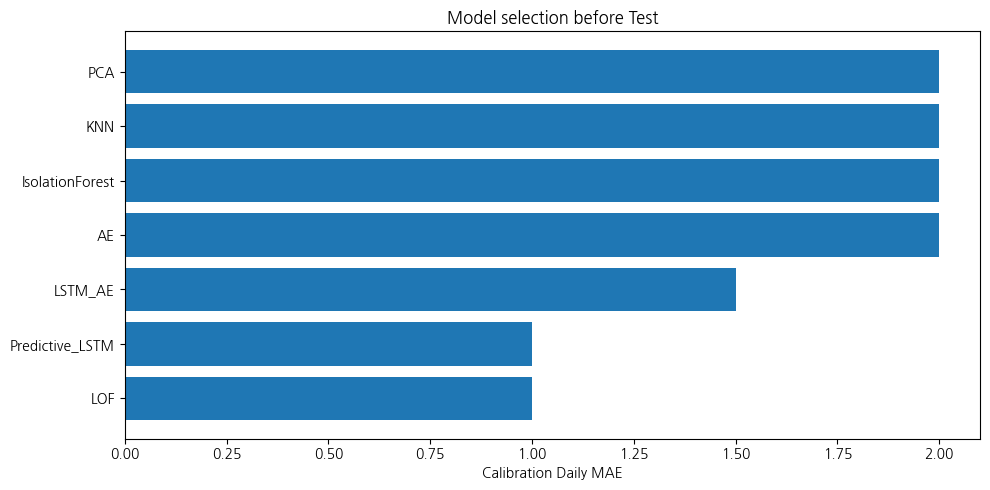

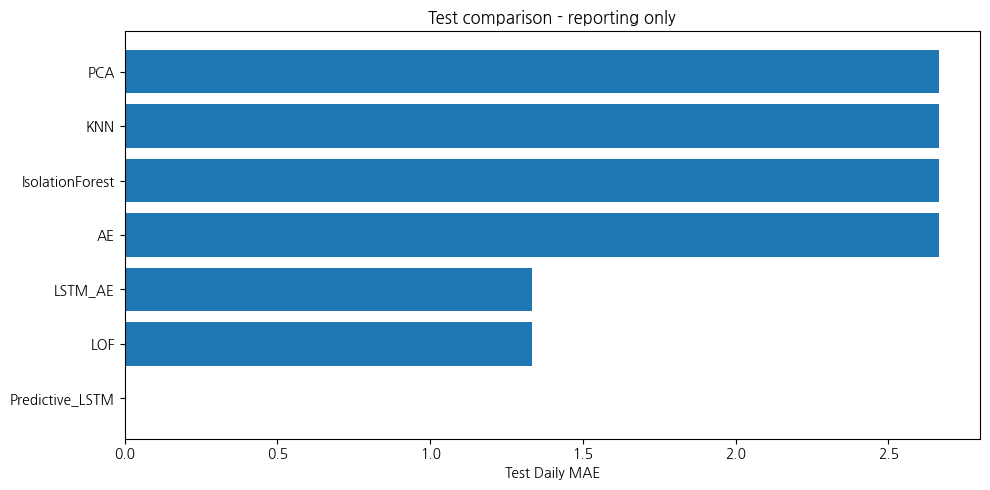

In [41]:

# 11. Compact comparison figures

plot_df = internal_ranking.sort_values("cal_daily_mae", ascending=True)
plt.figure(figsize=(10,5))
plt.barh(plot_df["model_name"], plot_df["cal_daily_mae"])
plt.xlabel("Calibration Daily MAE")
plt.title("Model selection before Test")
plt.tight_layout()
plt.savefig(DIRS["figures"] / "validation_model_ranking.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10,5))
show = test_ranking.sort_values("daily_mae", ascending=True)
plt.barh(show["model_name"], show["daily_mae"])
plt.xlabel("Test Daily MAE")
plt.title("Test comparison - reporting only")
plt.tight_layout()
plt.savefig(DIRS["figures"] / "test_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


In [42]:

# 12. 모든 모델 날짜별 실제 불량 vs 예측 이상탐지


model_names = [
    "AE",
    "IsolationForest",
    "LOF",
    "PCA",
    "KNN",
    "LSTM_AE",
    "Predictive_LSTM"
]

all_daily_rows = []

for model_name in model_names:

    daily = dailies[(model_name, "test")].copy()

    daily["count_diff"] = (
        daily["predicted_anomaly_count"]
        - daily["actual_defect_count"]
    )

    daily["abs_count_diff"] = daily["count_diff"].abs()

    daily["model_name"] = model_name

    all_daily_rows.append(
        daily[
            [
                "model_name",
                "date",
                "actual_defect_count",
                "predicted_anomaly_count",
                "count_diff",
                "abs_count_diff"
            ]
        ]
    )

    print("\n" + "=" * 65)
    print(f"{model_name} 날짜별 실제 불량 vs 예측 이상탐지")
    print("=" * 65)

    display(
        daily[
            [
                "date",
                "actual_defect_count",
                "predicted_anomaly_count",
                "count_diff",
                "abs_count_diff"
            ]
        ].rename(
            columns={
                "date": "일자",
                "actual_defect_count": "실제 불량건수",
                "predicted_anomaly_count": "예측 이상탐지건수",
                "count_diff": "건수 차이",
                "abs_count_diff": "절대오차"
            }
        )
    )


all_model_daily_compare = pd.concat(
    all_daily_rows,
    ignore_index=True
)

save_csv(
    all_model_daily_compare,
    DIRS["metrics"] / "all_models_holdout_daily_compare.csv"
)


AE 날짜별 실제 불량 vs 예측 이상탐지


,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,0,-4.0,4.0
1,2020-04-03,4.0,5,1.0,1.0
2,2020-04-07,3.0,0,-3.0,3.0



IsolationForest 날짜별 실제 불량 vs 예측 이상탐지


,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,0,-4.0,4.0
1,2020-04-03,4.0,5,1.0,1.0
2,2020-04-07,3.0,0,-3.0,3.0



LOF 날짜별 실제 불량 vs 예측 이상탐지


...

,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,0,-4.0,4.0
1,2020-04-03,4.0,5,1.0,1.0
2,2020-04-07,3.0,0,-3.0,3.0



LSTM_AE 날짜별 실제 불량 vs 예측 이상탐지


,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,5,1.0,1.0
1,2020-04-03,4.0,1,-3.0,3.0
2,2020-04-07,3.0,3,0.0,0.0



Predictive_LSTM 날짜별 실제 불량 vs 예측 이상탐지


,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,4,0.0,0.0
1,2020-04-03,4.0,4,0.0,0.0
2,2020-04-07,3.0,3,0.0,0.0


In [43]:

# 13. Model 1 최종 결과


final_row = tie_break_ranking.iloc[0]

print("=" * 70)
print("MODEL 1 최종 결과")
print("=" * 70)

print(f"최종 선정 모델 : {FINAL_SELECTED_MODEL}")
print(f"Holdout Daily MAE : {final_row['daily_mae']:.3f}")
print(f"Holdout Daily RMSE : {final_row['daily_rmse']:.3f}")
print(
    f"실제 총 불량건수 : "
    f"{int(final_row['actual_count_evaluated_days'])}건"
)
print(
    f"예측 총 이상탐지건수 : "
    f"{int(final_row['predicted_count_evaluated_days'])}건"
)

print("\n최종 모델 날짜별 결과")

display(
    selected_test_daily[
        [
            "date",
            "actual_defect_count",
            "predicted_anomaly_count",
            "error",
            "absolute_error"
        ]
    ].rename(
        columns={
            "date": "일자",
            "actual_defect_count": "실제 불량건수",
            "predicted_anomaly_count": "예측 이상탐지건수",
            "error": "건수 차이",
            "absolute_error": "절대오차"
        }
    )
)

print("\n최종 예측파일")
print(DIRS["predictions"] / "final_test_predictions.csv")

MODEL 1 최종 결과
최종 선정 모델 : Predictive_LSTM
Holdout Daily MAE : 0.000
Holdout Daily RMSE : 0.000
실제 총 불량건수 : 11건
예측 총 이상탐지건수 : 11건

최종 모델 날짜별 결과


,일자,실제 불량건수,예측 이상탐지건수,건수 차이,절대오차
0,2020-04-02,4.0,4,0.0,0.0
1,2020-04-03,4.0,4,0.0,0.0
2,2020-04-07,3.0,3,0.0,0.0



최종 예측파일
/home/kampuser/welder_source_code/Untitled Folder/outputs/20261008T125309_360963Z/predictions/final_test_predictions.csv


## 결과 해석 및 제출 안내

모델 구조와 학습 설정은 사전 고정하고, 딥러닝의 학습 종료 시점만 Early Stopping으로 결정했다. 모델별 임계값은 Calibration 집계 불량 건수로 보정한다. Calibration 공동 1위 모델만 후속 Holdout의 날짜별 절대 건수 차이로 2차 비교한다. 이 구간은 모델 선택에 사용되었으므로 완전 독립 평가가 아니다. 출력되는 3,469행의 anomaly_score 및 anomaly_flag는 개별 제품의 실제 불량 정답과 동일한 의미가 아니다.

Predictive LSTM의 이상탐지 건수는 **예측 가능한 3,439행** 기준이며, 첫 10개/일(총 30행)은 미예측으로 구분한다. 다른 6개 모델과 이상탐지 건수 비교 시 평가 대상 행 수 차이를 고려한다.
